# Titanic Survival Prediction

## 1. Project Objective

Use the Titanic passenger manifest to predict whether a passenger survived (`Survived`: 0 = did not survive, 1 = survived). This notebook compares Logistic Regression, Random Forest, and Gaussian Naive Bayes on the same reproducible, stratified 80/20 holdout split. Preprocessing is fitted within each model pipeline using training data only.

## 2. Import Libraries

The libraries below support data inspection, visualisation, preprocessing pipelines, classifiers, and evaluation. A fixed random seed is used wherever the models or split are stochastic.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
OUTPUT_DIR = Path("visualizations")
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"pandas: {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Visualizations will be saved to: {OUTPUT_DIR.resolve()}")

pandas: 3.1.0
scikit-learn: 1.9.1
Visualizations will be saved to: D:\gradious\MLAlgorithm\Titanic_Survival_ML\visualizations


## 3. Load and Explore Dataset

Read the supplied CSV without changing it. Verify the actual column names and target before proceeding. The overview reports dataset dimensions, data types, missing-value counts, target balance, and numeric summaries.

In [2]:
DATA_PATH = Path("Titanic-Dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Run the notebook from the project folder."
    )

raw_df = pd.read_csv(DATA_PATH)
expected_columns = [
    "PassengerId", "Survived", "Pclass", "Name", "Sex", "Age",
    "SibSp", "Parch", "Ticket", "Fare", "Cabin", "Embarked",
]
if list(raw_df.columns) != expected_columns:
    raise ValueError(
        "CSV schema does not match the verified Titanic dataset. "
        f"Expected {expected_columns}, found {list(raw_df.columns)}."
    )
if "Survived" not in raw_df.columns:
    raise ValueError("The required prediction target 'Survived' is missing.")

print(f"Dataset shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
display(raw_df.head())
display(raw_df.dtypes.rename("data_type").to_frame())
missing_counts = raw_df.isna().sum().sort_values(ascending=False)
display(missing_counts.rename("missing_values").to_frame())
display(raw_df["Survived"].value_counts().sort_index().rename("passengers").to_frame())
display(raw_df.describe(include="all").T)

Dataset shape: 891 rows x 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,data_type
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


,missing_values
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


,passengers
Survived,
0,549
1,342


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


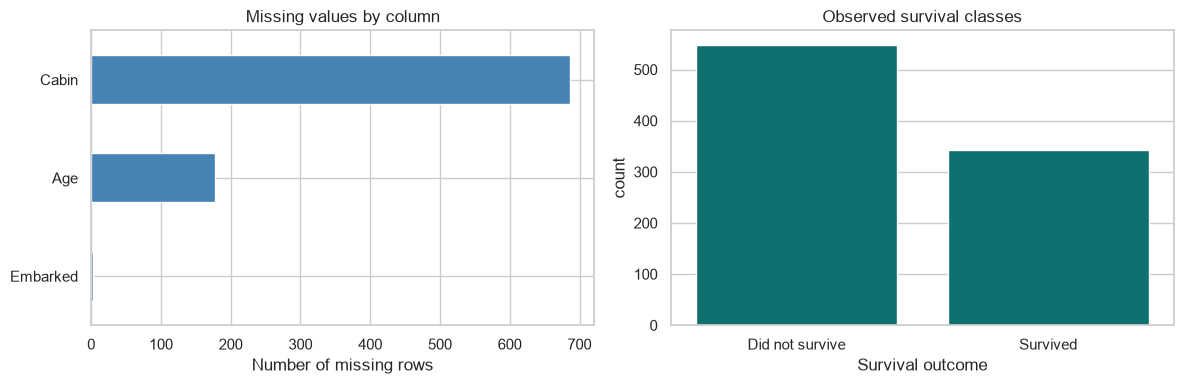

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
missing_counts[missing_counts > 0].sort_values().plot(
    kind="barh", ax=axes[0], color="steelblue"
)
axes[0].set_title("Missing values by column")
axes[0].set_xlabel("Number of missing rows")
sns.countplot(data=raw_df, x="Survived", ax=axes[1], color="teal")
axes[1].set_title("Observed survival classes")
axes[1].set_xticks([0, 1], labels=["Did not survive", "Survived"])
axes[1].set_xlabel("Survival outcome")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dataset_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Data Cleaning and Missing Values

The CSV has missing `Age` and `Embarked` values, while `Cabin` is missing for most passengers. Keep the source DataFrame unchanged and make a separate modeling copy. Median imputation for numeric columns and most-frequent imputation for categorical columns will be learned inside each training pipeline. `Cabin` is excluded because 687 of 891 values are missing; rows are not discarded.

In [4]:
model_data = raw_df.copy()
print("Missing-value counts in the untouched source data:")
display(model_data.isna().sum().rename("missing_values").to_frame())
print(
    f"Cabin missingness: {model_data['Cabin'].isna().sum()} / "
    f"{len(model_data)} rows "
    f"({model_data['Cabin'].isna().mean():.1%}); Cabin will be excluded."
)
print("No source rows are dropped. Missing feature values are imputed in model pipelines.")

Missing-value counts in the untouched source data:


,missing_values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Cabin missingness: 687 / 891 rows (77.1%); Cabin will be excluded.
No source rows are dropped. Missing feature values are imputed in model pipelines.


## 5. Outlier Analysis and Treatment

Use the IQR rule to describe potential outliers in `Age`, `Fare`, `SibSp`, and `Parch`, and inspect their distributions. These flags are exploratory, not grounds for deleting passengers. `Fare` is strongly right-skewed, so a `log1p` transformation is used as a feature in the next section. Other values are retained: the tree model is not sensitive to feature scaling, and the numeric pipelines impute missing values without removing records.

,lower_bound,upper_bound,flagged_rows
Age,-6.6875,64.8125,11.0
Fare,-26.7240,65.6344,116.0
SibSp,-1.5000,2.5000,46.0
Parch,0.0000,0.0000,213.0


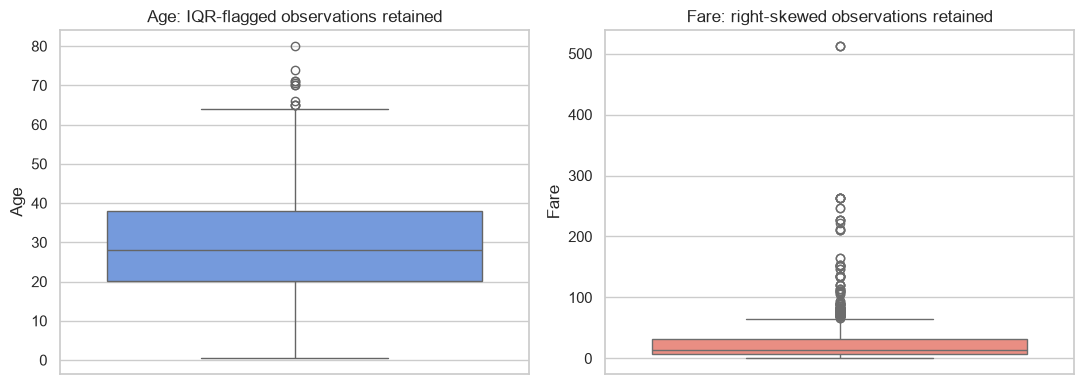

In [5]:
def iqr_outlier_summary(series):
    values = series.dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({
        "lower_bound": lower,
        "upper_bound": upper,
        "flagged_rows": int(((values < lower) | (values > upper)).sum()),
    })

outlier_summary = raw_df[["Age", "Fare", "SibSp", "Parch"]].apply(iqr_outlier_summary).T
display(outlier_summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(y=raw_df["Age"], ax=axes[0], color="cornflowerblue")
axes[0].set_title("Age: IQR-flagged observations retained")
sns.boxplot(y=raw_df["Fare"], ax=axes[1], color="salmon")
axes[1].set_title("Fare: right-skewed observations retained")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "outlier_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Feature Engineering and Selection

Create `FamilySize` and `IsAlone` from `SibSp` and `Parch`, and extract a passenger title from `Name`, grouping titles seen fewer than 10 times as `Rare`. Transform nonnegative fares with `log1p` to reduce skew. Exclude `PassengerId`, `Name`, `Ticket`, and `Cabin` because they are identifiers, high-cardinality text, or too incomplete; retain useful demographic, class, fare, and family features.

In [6]:
if (raw_df["Fare"].dropna() < 0).any():
    raise ValueError("Fare contains negative values, so log1p is not valid.")

model_data["Title"] = (
    model_data["Name"]
    .str.extract(r",\s*([^.]*)\.", expand=False)
    .fillna("Unknown")
    .str.strip()
)
title_counts = model_data["Title"].value_counts()
model_data["Title"] = model_data["Title"].where(
    model_data["Title"].map(title_counts) >= 10, "Rare"
)
model_data["FamilySize"] = model_data["SibSp"] + model_data["Parch"] + 1
model_data["IsAlone"] = (model_data["FamilySize"] == 1).astype(int)
model_data["Fare_log"] = np.log1p(model_data["Fare"])

numeric_features = ["Age", "SibSp", "Parch", "FamilySize", "IsAlone", "Fare_log"]
categorical_features = ["Pclass", "Sex", "Embarked", "Title"]
feature_columns = numeric_features + categorical_features
X = model_data[feature_columns].copy()
y = model_data["Survived"].astype(int).copy()

print(f"Selected features ({len(feature_columns)}): {feature_columns}")
display(X.head())
print("Target classes:", sorted(y.unique().tolist()))

Selected features (10): ['Age', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'Fare_log', 'Pclass', 'Sex', 'Embarked', 'Title']


,Age,SibSp,Parch,FamilySize,IsAlone,Fare_log,Pclass,Sex,Embarked,Title
0,22.0,1,0,2,0,2.110213,3,male,S,Mr
1,38.0,1,0,2,0,4.280593,1,female,C,Mrs
2,26.0,0,0,1,1,2.188856,3,female,S,Miss
3,35.0,1,0,2,0,3.990834,1,female,S,Mrs
4,35.0,0,0,1,1,2.202765,3,male,S,Mr


Target classes: [0, 1]


## 7. Train-Test Split

Reserve 20% of rows for the final holdout evaluation. Stratification preserves the observed survival-class proportions, and `random_state=42` makes the split reproducible. The test set is not used to fit preprocessing or models.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print("Training survival proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Test survival proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Training rows: 712
Test rows: 179
Training survival proportions:


,proportion
Survived,
0,0.616573
1,0.383427


Test survival proportions:


,proportion
Survived,
0,0.614525
1,0.385475


## 8. Preprocessing and Encoding

Each classifier gets a scikit-learn `Pipeline` and `ColumnTransformer`. Numeric and categorical imputers, one-hot encoders, and scalers are fitted only when the pipeline is trained on `X_train`. Logistic Regression and Gaussian Naive Bayes use scaled numeric features; Random Forest uses unscaled numeric features. Gaussian Naive Bayes receives a dense encoded matrix, as required by that estimator.

In [8]:
def make_preprocessor(scale_numeric, dense_output=True):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(steps=numeric_steps)
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=not dense_output,
        )),
    ])
    return ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ])

logistic_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
forest_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
naive_bayes_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor(scale_numeric=True, dense_output=True)),
    ("classifier", GaussianNB()),
])

print("All three complete preprocessing-and-model pipelines are ready.")

All three complete preprocessing-and-model pipelines are ready.


## 9. Logistic Regression Model

Logistic Regression estimates survival probability from a linear combination of the engineered and encoded features. Scaling numeric inputs helps the optimizer handle features with different units. The pipeline is fitted on the training partition and evaluated on the untouched test partition.

In [9]:
models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": forest_pipeline,
    "Gaussian Naive Bayes": naive_bayes_pipeline,
}
predictions = {}
results = {}

def evaluate_model(name, pipeline):
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
    }
    return results[name]

logistic_metrics = evaluate_model("Logistic Regression", logistic_pipeline)
print("Logistic Regression test metrics:")
display(pd.Series(logistic_metrics).rename("score").to_frame())

Logistic Regression test metrics:


,score
Accuracy,0.843575
Precision,0.825397
Recall,0.753623
F1-score,0.787879


## 10. Random Forest Classifier

Random Forest combines many decision trees trained on bootstrapped samples and feature subsets. It can learn nonlinear patterns and does not require numeric scaling. Its imputation and categorical encoding are still learned inside the training-only pipeline.

In [10]:
forest_metrics = evaluate_model("Random Forest", forest_pipeline)
print("Random Forest test metrics:")
display(pd.Series(forest_metrics).rename("score").to_frame())

Random Forest test metrics:


,score
Accuracy,0.821229
Precision,0.784615
Recall,0.739130
F1-score,0.761194


## 11. Gaussian Naive Bayes Classifier

Gaussian Naive Bayes applies Bayes' rule with a conditional-independence assumption and Gaussian numeric feature likelihoods. Its pipeline standardizes numeric columns and produces dense one-hot encoded categories before fitting and prediction.

In [11]:
naive_bayes_metrics = evaluate_model(
    "Gaussian Naive Bayes", naive_bayes_pipeline
)
print("Gaussian Naive Bayes test metrics:")
display(pd.Series(naive_bayes_metrics).rename("score").to_frame())

Gaussian Naive Bayes test metrics:


,score
Accuracy,0.810056
Precision,0.739726
Recall,0.782609
F1-score,0.760563


## 12. Model Evaluation and Comparison

Compare all models on the same held-out rows using accuracy, precision, recall, and F1-score for the positive class (`Survived = 1`). The table displays the measured test-set values; no cross-validation or test-set tuning is performed.

In [12]:
comparison_df = pd.DataFrame.from_dict(results, orient="index")
comparison_df.index.name = "Model"
comparison_df = comparison_df.sort_values(
    ["F1-score", "Recall", "Accuracy"],
    ascending=False,
)
display(comparison_df.round(3))
print(f"Evaluated {len(y_test)} held-out passengers.")

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.844,0.825,0.754,0.788
Random Forest,0.821,0.785,0.739,0.761
Gaussian Naive Bayes,0.810,0.740,0.783,0.761


Evaluated 179 held-out passengers.


## 13. Confusion Matrices

Each confusion matrix shows actual versus predicted survival labels on the same test split. The plots are saved in `visualizations/` for reuse in the PDF report.

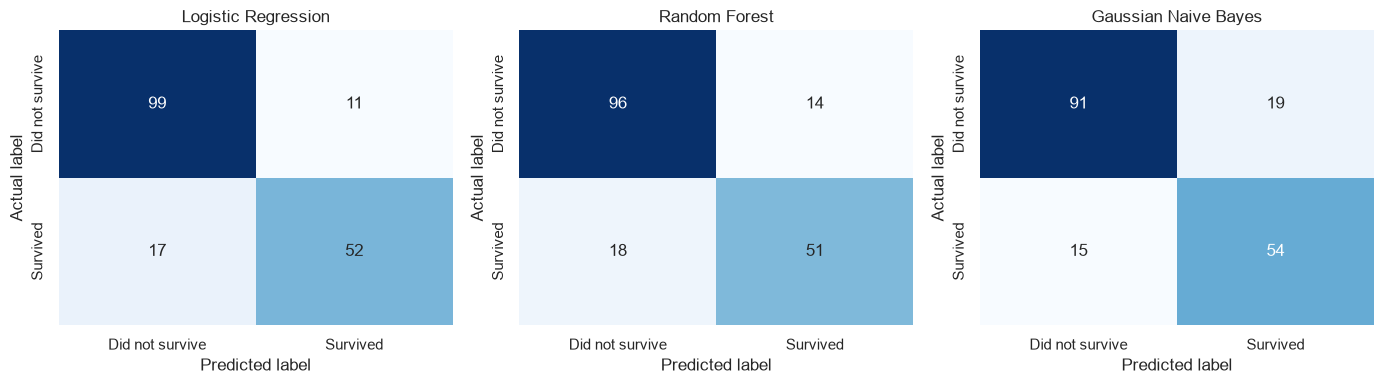

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, (name, y_pred) in zip(axes, predictions.items()):
    matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Did not survive", "Survived"],
        yticklabels=["Did not survive", "Survived"],
        ax=axis,
    )
    axis.set_title(name)
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("Actual label")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Final Model Selection

Select the final model using the observed holdout results: highest F1-score, then recall, then accuracy as tie-breakers. This prioritizes a balance between precision and recall for the survival class while making the decision rule explicit and reproducible.

In [14]:
final_model_name = max(
    results,
    key=lambda name: (
        results[name]["F1-score"],
        results[name]["Recall"],
        results[name]["Accuracy"],
    ),
)
final_metrics = results[final_model_name]
print(f"Selected model from actual test results: {final_model_name}")
print(
    f"F1-score={final_metrics['F1-score']:.3f}, "
    f"Recall={final_metrics['Recall']:.3f}, "
    f"Accuracy={final_metrics['Accuracy']:.3f}"
)

Selected model from actual test results: Logistic Regression
F1-score=0.788, Recall=0.754, Accuracy=0.844


## 15. Conclusion

Summarize the observed comparison and selected model. Results describe this single stratified holdout split, not guaranteed performance on new populations. Limitations include a small historical dataset, class imbalance, coarse feature engineering, missing cabin information, and the absence of external validation.

In [15]:
print(
    f"On this {len(y_test)}-passenger holdout set, {final_model_name} "
    f"was selected by the stated F1/recall/accuracy rule "
    f"(F1={final_metrics['F1-score']:.3f})."
)
print(
    "Limitations: small historical sample; one fixed train-test split; "
    "high Cabin missingness; engineered features may omit useful detail; "
    "results may not generalize beyond this dataset."
)

On this 179-passenger holdout set, Logistic Regression was selected by the stated F1/recall/accuracy rule (F1=0.788).
Limitations: small historical sample; one fixed train-test split; high Cabin missingness; engineered features may omit useful detail; results may not generalize beyond this dataset.


### Summary Report

The final cell creates `Summary_Report.pdf` only after fitting all three models and calculating their real holdout metrics. The report includes the dataset and methodology, model descriptions, the measured comparison, saved visualizations, limitations, and the data-driven conclusion.

In [16]:
from matplotlib.backends.backend_pdf import PdfPages
from textwrap import wrap

report_path = Path("Summary_Report.pdf")

def add_text_page(pdf, title, paragraphs):
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(0.08, 0.94, title, fontsize=18, weight="bold", va="top")
    y_position = 0.88
    for paragraph in paragraphs:
        lines = wrap(paragraph, width=95)
        fig.text(0.08, y_position, "\n".join(lines), fontsize=10.5, va="top", linespacing=1.5)
        y_position -= 0.035 * (len(lines) + 1)
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

with PdfPages(report_path) as pdf:
    add_text_page(pdf, "Titanic Survival Prediction", [
        "Problem: predict the binary Survived outcome (0 = did not survive, 1 = survived) "
        "from passenger-manifest information.",
        f"Dataset: {raw_df.shape[0]} passengers and {raw_df.shape[1]} source columns. "
        "Verified columns: PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, "
        "Parch, Ticket, Fare, Cabin, Embarked.",
        f"Missing values in this CSV: Age={raw_df['Age'].isna().sum()}, "
        f"Cabin={raw_df['Cabin'].isna().sum()}, "
        f"Embarked={raw_df['Embarked'].isna().sum()}. Cabin was excluded due to "
        "its high missingness; no passenger rows were removed.",
        "Methodology: stratified 80/20 train-test split with random_state=42. "
        "Median numeric and most-frequent categorical imputation, one-hot encoding, "
        "and scaling where appropriate are fitted only within training pipelines.",
        "Feature engineering: family size, alone indicator, grouped name title, and "
        "log1p fare. IQR flags were inspected but passengers were not removed; log1p "
        "was used to reduce fare skew.",
    ])

    fig, axis = plt.subplots(figsize=(9, 3.5))
    axis.axis("off")
    table = axis.table(
        cellText=np.round(comparison_df.to_numpy(), 3),
        rowLabels=comparison_df.index,
        colLabels=comparison_df.columns,
        loc="center",
        cellLoc="center",
        rowLoc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.8)
    axis.set_title("Actual holdout test results", pad=18, fontsize=14, weight="bold")
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    add_text_page(pdf, "Algorithms and Model Selection", [
        "Logistic Regression: linear probabilistic classifier; numeric features scaled.",
        "Random Forest: ensemble of 300 decision trees; numeric features not scaled.",
        "Gaussian Naive Bayes: probabilistic classifier with a conditional-independence "
        "assumption; numeric features scaled and categorical encoding densified.",
        f"Selection rule: highest holdout F1-score, then recall, then accuracy. "
        f"The selected model is {final_model_name}, with accuracy "
        f"{final_metrics['Accuracy']:.3f}, precision {final_metrics['Precision']:.3f}, "
        f"recall {final_metrics['Recall']:.3f}, and F1-score "
        f"{final_metrics['F1-score']:.3f}.",
        "Limitations: this is a small historical dataset and a single holdout split. "
        "The results are not external validation or a guarantee of future performance. "
        "High Cabin missingness and simplified feature engineering may limit prediction.",
        "Conclusion: the selected model is the strongest under the stated metric rule "
        "on this test split. More validation and careful assessment of generalization "
        "would be needed before real-world use.",
    ])

    visual_paths = [
        OUTPUT_DIR / "dataset_overview.png",
        OUTPUT_DIR / "outlier_analysis.png",
        OUTPUT_DIR / "confusion_matrices.png",
    ]
    fig, axes = plt.subplots(len(visual_paths), 1, figsize=(9, 14))
    for axis, image_path in zip(axes, visual_paths):
        image = plt.imread(image_path)
        axis.imshow(image)
        axis.set_title(image_path.stem.replace("_", " ").title())
        axis.axis("off")
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

print(f"Created report from executed test results: {report_path.resolve()}")
print(f"Report size: {report_path.stat().st_size:,} bytes")

Created report from executed test results: D:\gradious\MLAlgorithm\Titanic_Survival_ML\Summary_Report.pdf
Report size: 123,453 bytes
